# 01 — Datos: universos, ingesta, limpieza, validación y split

**Dueño:** Juan Manuel Espinosa (JME) · **Revisor:** Gonzalo Cano (GC) · **Guía:** `docs/instrucciones/01_datos.md`

**Objetivo.** Obtener 10–15 años de precios diarios ajustados de los dos universos candidatos, limpiarlos y
validarlos, y fijar la partición cronológica 60 / 20 / 20 (entrenamiento / prueba / validación) **antes** de
cualquier estimación.

> Este notebook solo **muestra**: toda la lógica vive en `data/` y `cointegration/universe.py`, y es la misma
> que ejecuta `python main.py`.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd

from cointegration.universe import UNIVERSES, all_tickers
from data.clean import MAX_FFILL, clean_prices
from data.download import download_prices, load_prices
from data.split import SPLIT, SPLIT_NAMES, compute_split_dates, label_split, load_split_dates, slice_split
from data.validate import JUMP_THRESHOLD, validate_prices
from main import ARTIFACTS, DATA_SNAPSHOT, END_DATE, FIGURES, START_DATE
from performance.figures import plot_normalized_prices

pd.set_option("display.width", 140)
print(f"Ventana: {START_DATE} → {END_DATE}")

Ventana: 2012-01-01 → 2026-10-30


## 1. Universos candidatos

Paso 1 de §3.2: cada integrante aporta un universo con justificación económica. Esa justificación es la defensa
contra el problema de pruebas múltiples (se prueban solo grupos con una razón para compartir tendencia).

In [2]:
rows = [
    {"universo": u, "dueño": spec["owner"], "ticker": t, "nombre": spec["names"][t]}
    for u, spec in UNIVERSES.items() for t in spec["tickers"]
]
pd.DataFrame(rows)

,universo,dueño,ticker,nombre
0,petroleras,JME,XOM,Exxon Mobil
1,petroleras,JME,CVX,Chevron
2,petroleras,JME,COP,ConocoPhillips
3,petroleras,JME,OXY,Occidental Petroleum
4,petroleras,JME,EOG,EOG Resources
5,petroleras,JME,DVN,Devon Energy
6,petroleras,JME,APA,APA Corp.
7,petroleras,JME,BP,BP (ADR)
8,petroleras,JME,SHEL,Shell (ADR)
9,oro,GC,GLD,SPDR Gold Shares (ETF de oro físico)


In [3]:
for name, spec in UNIVERSES.items():
    print(f"■ {name.upper()} ({spec['owner']}) — {len(spec['tickers'])} activos")
    print(f"  Justificación: {spec['rationale']}")
    for ticker, reason in spec["excluded"].items():
        print(f"  Excluido {ticker}: {reason}")
    print()

■ PETROLERAS (JME) — 9 activos
  Justificación: Petroleras de EE. UU. y Europa: todas venden el mismo producto (crudo y gas), así que el precio del petróleo es una tendencia estocástica común. Lo que las separa es temporal (costos de extracción, deuda, coberturas) y es lo que debería revertir. Las europeas se toman como ADR en dólares para evitar el ruido cambiario y la diferencia de horarios de cierre.
  Excluido HES: Hess: adquirida por Chevron (2025); sesgo de supervivencia / huecos en los datos
  Excluido MRO: Marathon Oil: adquirida por ConocoPhillips (2024)
  Excluido PXD: Pioneer Natural Resources: adquirida por Exxon Mobil (2024)

■ ORO (GC) — 8 activos
  Justificación: Mineras de oro más el metal: el ingreso de las mineras es el precio del oro, así que comparten su tendencia estocástica. El apalancamiento operativo y las coberturas hacen que la relación cambie en el tiempo, que es lo que rastrea el filtro 1. GLD/GDX es el ejemplo clásico de Chan (2013).
  Excluido GOLD: El tic

## 2. Ingesta

`load_prices` lee el snapshot versionado `data/snapshot/prices_raw.parquet`; solo descarga de Yahoo Finance si el
snapshot no existe o no cubre lo pedido. Precios **ajustados** por splits y dividendos: sin ajuste, un split parece
una ruptura de la cointegración.

In [4]:
raw = load_prices(all_tickers(), START_DATE, END_DATE, DATA_SNAPSHOT)
history = pd.DataFrame({
    "primera fecha": raw.apply(lambda s: s.first_valid_index().date()),
    "última fecha": raw.apply(lambda s: s.last_valid_index().date()),
    "días con precio": raw.notna().sum(),
})
print(f"{raw.shape[0]} días × {raw.shape[1]} activos")
history

3729 días × 17 activos


,primera fecha,última fecha,días con precio
XOM,2012-01-03,2026-10-30,3729
CVX,2012-01-03,2026-10-30,3729
COP,2012-01-03,2026-10-30,3729
OXY,2012-01-03,2026-10-30,3729
EOG,2012-01-03,2026-10-30,3729
DVN,2012-01-03,2026-10-30,3729
APA,2012-01-03,2026-10-30,3729
BP,2012-01-03,2026-10-30,3729
SHEL,2012-01-03,2026-10-30,3729
GLD,2012-01-03,2026-10-30,3729


### Verificación de tickers: `GOLD` ya no es Barrick

Al revisar la historia de cada ticker apareció que `GOLD` hoy corresponde a **Gold.com, Inc.** y empieza en 2014;
Barrick Mining cotiza como **`B`**, con historia completa. Usar `GOLD` habría metido otra empresa al universo de oro.

In [5]:
check = download_prices(["GOLD", "B"], START_DATE, END_DATE)
pd.DataFrame({
    "primera fecha": check.apply(lambda s: s.first_valid_index().date()),
    "precio al cierre de 2018": check.loc[:"2018-12-31"].iloc[-1].round(2),
    "en el universo": ["no (Gold.com)", "sí (Barrick)"],
})

,primera fecha,precio al cierre de 2018,en el universo
GOLD,2014-03-17,4.29,no (Gold.com)
B,2012-01-03,11.31,sí (Barrick)


## 3. Limpieza y validación

- **Limpieza** (`data/clean.py`): orden, sin fechas duplicadas, forward-fill de a lo más `MAX_FFILL` días y
  después intersección de calendarios. **Nunca back-fill**: rellenar hacia atrás usa precios futuros.
- **Validación** (`data/validate.py`): sin NaN, precios positivos, sin duplicados, índice ordenado, y reporte de
  saltos con |rendimiento log| mayor a `JUMP_THRESHOLD` (se reportan, no se borran).

In [6]:
prices, clean_report = clean_prices(raw)
report = validate_prices(prices)
print("Limpieza:", clean_report)
print("Validación:", {k: v for k, v in report.to_dict().items() if k != "jumps"})
print(f"Válido: {report.is_valid}")

Limpieza: {'rows_raw': 3729, 'duplicates_removed': 0, 'filled_cells': {}, 'rows_dropped': 0, 'rows_clean': 3729, 'max_ffill': 3}
Validación: {'n_rows': 3729, 'start': '2012-01-03', 'end': '2026-10-30', 'n_nan': 0, 'n_nonpositive': 0, 'n_duplicates': 0, 'is_sorted': True, 'is_valid': True}
Válido: True


In [7]:
print(f"Saltos con |rend. log| > {JUMP_THRESHOLD}:")
report.jumps

Saltos con |rend. log| > 0.4:


,date,ticker,log_return
0,2020-03-09,OXY,-0.734257
1,2020-03-09,DVN,-0.468359
2,2020-03-09,APA,-0.773593


Los tres saltos son del **9 de marzo de 2020** (guerra de precios del petróleo entre Arabia Saudita y Rusia, en
pleno inicio del COVID): son eventos reales y se conservan. Son relevantes para el análisis de
"estructural vs artefacto" del universo de petroleras.

## 4. Partición cronológica 60 / 20 / 20

Las fechas de corte se calculan **una sola vez** sobre el calendario completo y se congelan en
`artifacts/split_dates.json`. Todas las etapas cortan por fecha: al truncar los datos en *t* para la prueba de
causalidad, el entrenamiento no se mueve.

In [8]:
dates = compute_split_dates(prices.index)
split_table = pd.DataFrame([
    {"partición": name, "inicio": dates.bounds(name)[0].date(), "fin": dates.bounds(name)[1].date(),
     "días": len(slice_split(prices, dates, name))}
    for name in SPLIT_NAMES
])
split_table["% del total"] = (100 * split_table["días"] / len(prices)).round(1)
split_table

,partición,inicio,fin,días,% del total
0,train,2012-01-03,2020-11-19,2237,60.0
1,test,2020-11-20,2023-11-08,746,20.0
2,validation,2023-11-09,2026-10-30,746,20.0


In [9]:
frozen = load_split_dates(ARTIFACTS / "split_dates.json")
print("Coincide con artifacts/split_dates.json (escrito por main.py):", frozen == dates)

Coincide con artifacts/split_dates.json (escrito por main.py): True


## 5. Figura — precios normalizados por universo

Precios en base 100 al inicio de la muestra, en escala log, con las tres particiones sombreadas. La función es
`performance.figures.plot_normalized_prices`, la misma que genera la **figura 1** del grupo elegido (sección 7).

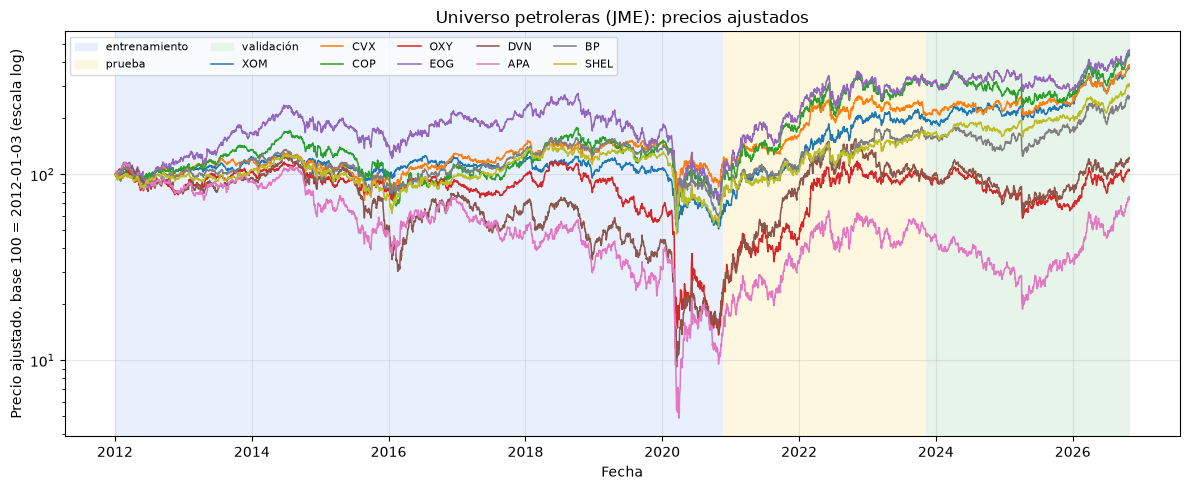

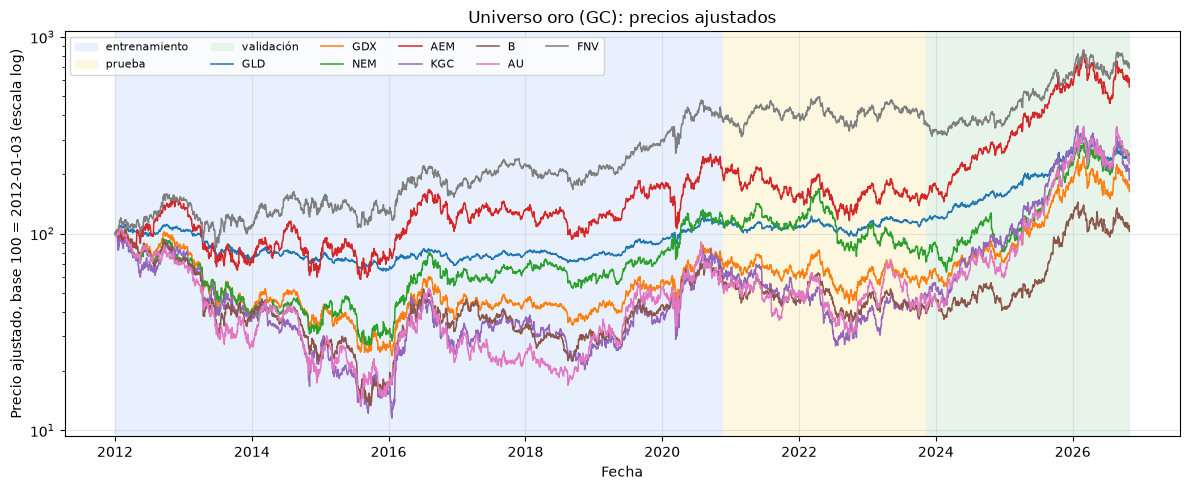

In [10]:
split = label_split(prices.index, dates)
for name, spec in UNIVERSES.items():
    plot_normalized_prices(prices[spec["tickers"]], split, f"Universo {name} ({spec['owner']}): precios ajustados")
    plt.show()

## 6. Verificaciones del criterio de terminado

In [11]:
labels = label_split(prices.index, dates)
checks = {
    "ventana de 10 a 15 años": 10 <= (prices.index[-1] - prices.index[0]).days / 365.25 <= 15,
    "sin NaN tras la limpieza": prices.isna().sum().sum() == 0,
    "precios positivos": (prices > 0).all().all(),
    "índice ordenado y sin duplicados": prices.index.is_monotonic_increasing and not prices.index.duplicated().any(),
    "particiones sin traslape y en orden": dates.train_end < dates.test_start and dates.test_end < dates.validation_start,
    "cada fecha tiene exactamente una partición": labels.notna().all(),
    "proporciones ≈ 60/20/20": all(abs(split_table["% del total"].values / 100 - SPLIT) < 0.01),
    "fechas iguales a las congeladas por main.py": frozen == dates,
}
for name, ok in checks.items():
    print(("✓" if ok else "✗"), name)
assert all(checks.values())

✓ ventana de 10 a 15 años
✓ sin NaN tras la limpieza
✓ precios positivos
✓ índice ordenado y sin duplicados
✓ particiones sin traslape y en orden
✓ cada fecha tiene exactamente una partición
✓ proporciones ≈ 60/20/20
✓ fechas iguales a las congeladas por main.py


## 7. Qué sigue: lo que recibe la parte 02 y lo que devuelve

La parte 02 (GC) corre el embudo de selección **solo sobre entrenamiento**, para ambos universos:

```python
from data.split import load_split_dates, slice_split
dates = load_split_dates(ARTIFACTS / "split_dates.json")
train = slice_split(prices, dates, "train")   # 2012-01-03 → 2020-11-19
```

Prueba y validación no se tocan hasta evaluar. La parte 02 eligió el grupo **GLD-GDX-AEM-FNV** (universo de oro;
detalle en `notebooks/02_seleccion_grupo.ipynb` y `artifacts/johansen_summary.json`). Con ese grupo, `main.py` escribe
`artifacts/prices.parquet`: precios limpios de los 4 activos con la columna `split` (`data.split.add_split_column`).
Es la entrada del filtro 1 (parte 03). `main.py` también genera la **figura 1** con esos 4 activos.

In [12]:
group_prices = pd.read_parquet(ARTIFACTS / "prices.parquet")
print(f"artifacts/prices.parquet: {group_prices.shape[0]} días, columnas {list(group_prices.columns)}")
print("Días por partición:", group_prices["split"].value_counts(sort=False).to_dict())
print("Coincide con los precios limpios:", group_prices.drop(columns="split").equals(prices[group_prices.columns.drop("split")]))
group_prices.head()

artifacts/prices.parquet: 3729 días, columnas ['GLD', 'GDX', 'AEM', 'FNV', 'split']
Días por partición: {'train': 2237, 'test': 746, 'validation': 746}
Coincide con los precios limpios: True


,GLD,GDX,AEM,FNV,split
date,,,,,
2012-01-03,155.919998,47.123398,29.698507,32.485409,train
2012-01-04,156.710007,47.070854,29.100979,33.243439,train
2012-01-05,157.779999,47.210995,29.457968,33.428738,train
2012-01-06,157.199997,46.729256,29.302752,33.496109,train
2012-01-09,156.500000,46.992016,29.520037,33.605602,train


### Figura 1 — precios del grupo elegido

Generada por `main.py` en `docs/figuras/fig01_precios_grupo.png`. GLD es el metal y las otras tres son mineras o
regalías de oro: comparten la tendencia del precio del oro, pero las mineras amplifican sus movimientos.

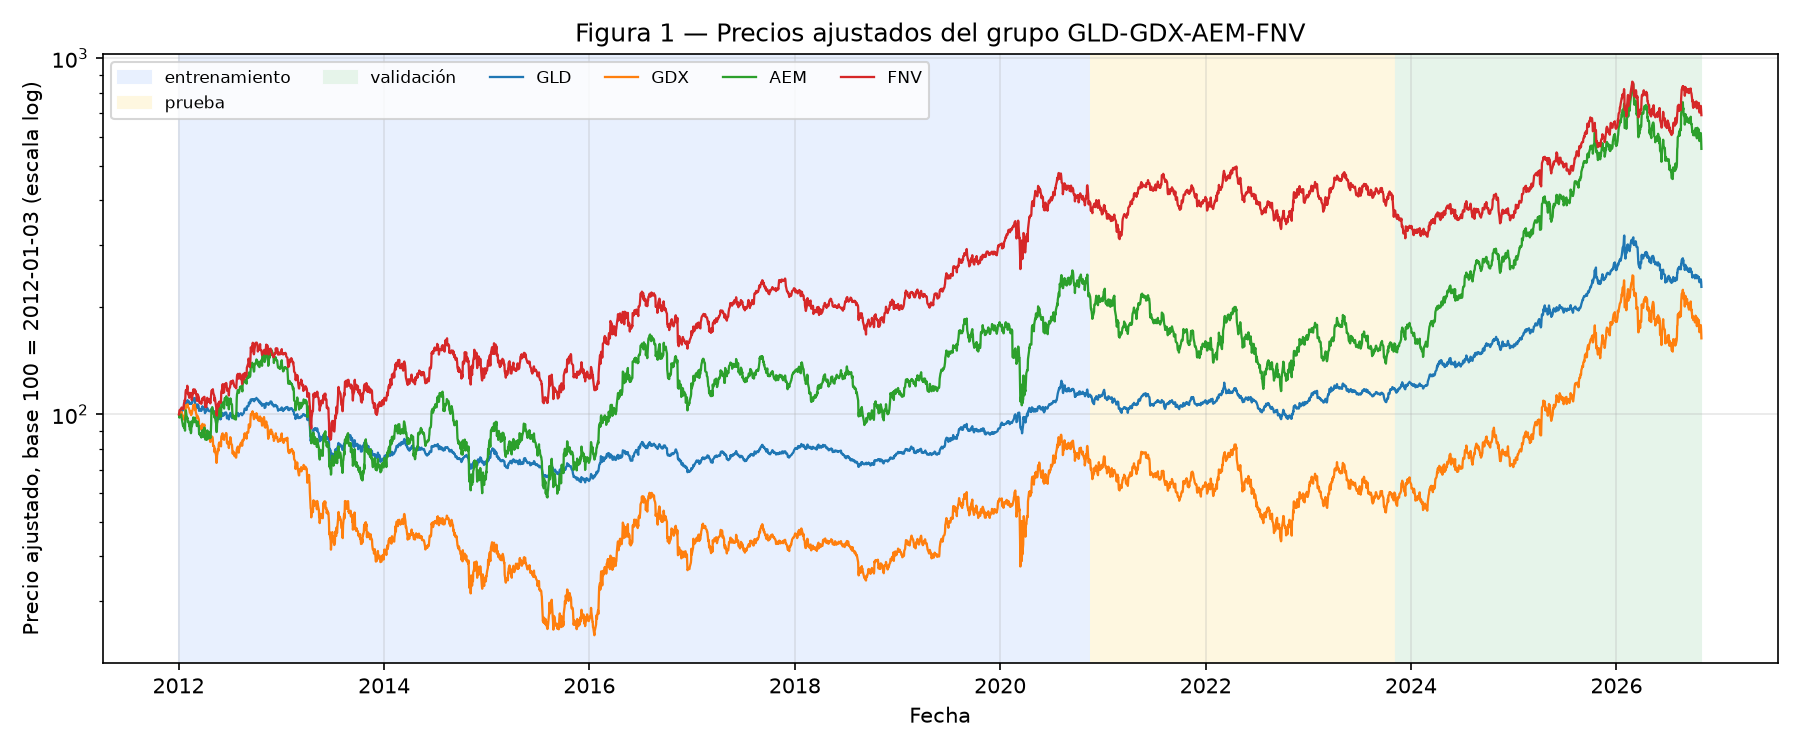

In [13]:
from IPython.display import Image, display

display(Image(filename=str(FIGURES / "fig01_precios_grupo.png")))

## Resumen de resultados (parte 01)

| Resultado | Valor |
|---|---|
| Universos | 2 con justificación económica: petroleras de EE. UU. y Europa (9) y oro + mineras (8) → 17 activos |
| Fuente | Yahoo Finance, precios ajustados por splits y dividendos, snapshot versionado (reproducible sin internet) |
| Ventana | 2012-01-03 → 2026-10-30 (≈ 14.8 años, dentro de 10–15) |
| Datos | 3 729 días hábiles, todos los activos con historia completa |
| Limpieza | 0 celdas rellenadas, 0 fechas eliminadas, 0 duplicados (forward-fill máximo de 3 días, nunca back-fill) |
| Validación | sin NaN, precios positivos, índice ordenado → válida |
| Saltos > 40 % (log) | 3, todos el 2020-03-09 (OXY, DVN, APA: guerra de precios del petróleo); se conservan |
| Entrenamiento | 2012-01-03 → 2020-11-19, 2 237 días (60 %) |
| Prueba | 2020-11-20 → 2023-11-08, 746 días (20 %) |
| Validación | 2023-11-09 → 2026-10-30, 746 días (20 %) |

- **Corrección de ticker:** `GOLD` hoy es Gold.com, Inc. (desde 2014); Barrick se usa como `B`.
- **Sin look-ahead:** las fechas de corte se calcularon una vez sobre el calendario completo y quedaron congeladas
  en `artifacts/split_dates.json`; todas las etapas cortan por fecha.
- **Entrega a las siguientes partes:** `artifacts/prices.parquet` con el grupo elegido en la parte 02 (GLD, GDX,
  AEM, FNV) y la columna `split`.
- **Figura 1:** precios de los 4 activos del grupo, `docs/figuras/fig01_precios_grupo.png`.